# Mock spectra Tests
This file is designed as testing space for booting up various mock spectra code

In [1]:
import matplotlib.pyplot as plt
import astropy
from astropy import units as u
import numpy as np
from common.pickles import load_pickle
import time
import os
import sys
import os
import pandas as pd
from unyt import Msun, yr, deg, km, s, cm, kelvin, Myr
import six
import yt

#import fsps

In [2]:
# Synthesizer
import synthesizer
print('Synthesizer imported:', synthesizer.__file__)


Synthesizer imported: /opt/miniconda3/envs/main_conda/lib/python3.15/site-packages/synthesizer/__init__.py


Loaded all_galaxy_properties.pkl: all_galaxy_properties.pkl  (154977 entries)
Total galaxies in catalog : 154977
Galaxies with a BH        : 40557


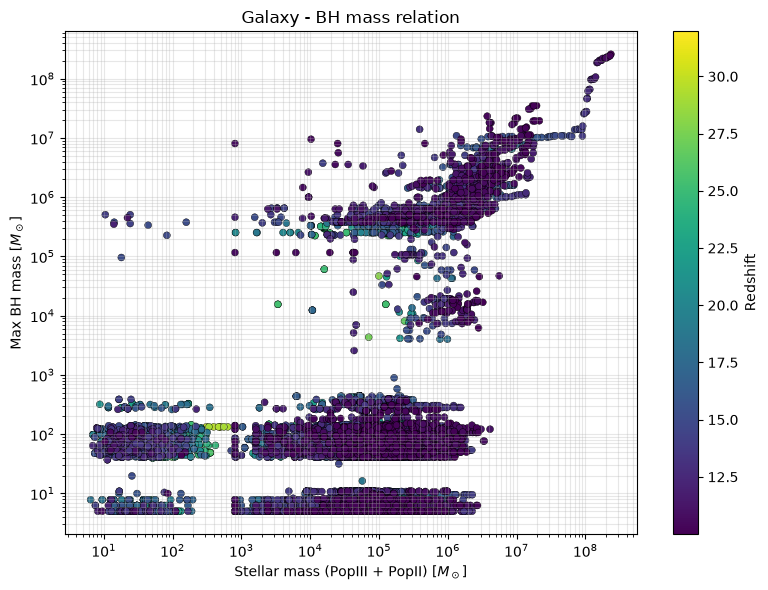

Saved -> galaxy_bh_mass_relation.png


In [7]:

"""
galaxy_catalog_example.py

Plots total stellar mass (PopIII + PopII) vs total BH mass for galaxies
in the catalog that host at least one BH, colored by redshift.
"""


def main():
    catalog_path = "all_galaxy_properties.pkl"
    output_path = "galaxy_bh_mass_relation.png"
    galaxies = load_pickle(catalog_path, "all_galaxy_properties.pkl")

    stellar_mass, bh_mass, redshift = [], [], []

    for galID, g in galaxies.items():
        m_bh = g.get("BHMass_Max", 0.0)
        if not m_bh or m_bh <= 0:
            continue

        m_star = g.get("PopIIIMass", 0.0) + g.get("PopIIMass", 0.0)
        stellar_mass.append(m_star)
        bh_mass.append(m_bh)
        redshift.append(g.get("Redshift", np.nan))

    print(f"Total galaxies in catalog : {len(galaxies)}")
    print(f"Galaxies with a BH        : {len(bh_mass)}")

    if not bh_mass:
        print("No BH-hosting galaxies found - nothing to plot.")
        return

    stellar_mass = np.array(stellar_mass)
    bh_mass = np.array(bh_mass)
    redshift = np.array(redshift)

    fig, ax = plt.subplots(figsize=(8, 6))
    sc = ax.scatter(stellar_mass, bh_mass, c=redshift, cmap="viridis",
                    s=25, edgecolor="k", linewidth=0.3)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"Stellar mass (PopIII + PopII) [$M_\odot$]")
    ax.set_ylabel(r"Max BH mass [$M_\odot$]")
    ax.set_title("Galaxy - BH mass relation")
    ax.grid(alpha=0.3, which="both")

    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label("Redshift")
    fig.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"Saved -> {output_path}")


main()

In [3]:
galaxy_catalogue = load_pickle("all_galaxy_properties.pkl", "all_galaxy_properties.pkl")

z=0
highest_mass = 0
highest_redshift = 0
highest_bh_mass = 0
highest_mass_redshift_over_10 = 0
for key in galaxy_catalogue.keys():
    #mass
    total_mass = galaxy_catalogue[key]['GasMass'] + galaxy_catalogue[key]['HaloMass'] + galaxy_catalogue[key]['PopIIIMass'] + galaxy_catalogue[key]['PopIIMass'] + galaxy_catalogue[key]['BHMass_Total']
    if total_mass > highest_mass:
        highest_mass = total_mass
        highest_mass_galaxy = galaxy_catalogue[key]
    #redshift
    if int(galaxy_catalogue[key]['Redshift']) > highest_redshift:
        highest_redshift = int(galaxy_catalogue[key]['Redshift'])
        highest_redshift_galaxy = galaxy_catalogue[key]
    # black hole mass
    if int(galaxy_catalogue[key]['BHMass_Total']) > highest_bh_mass:
        highest_bh_mass =  galaxy_catalogue[key]['BHMass_Total']
        highest_bh_mass_galaxy = galaxy_catalogue[key]

    z+=1


Loaded all_galaxy_properties.pkl: all_galaxy_properties.pkl  (154977 entries)


{'GalaxyID': 'snap000_Fallback_0',
 'Snapshot': 0,
 'Redshift': np.float64(39.90455460910629),
 'Center_code': [20250.379851752994, 20057.925987381677, 19900.230734071614],
 'GasMass': 5467036.6681386065,
 'HaloMass': 19211166.819212794,
 'PopIIIMass': 0.0,
 'PopIIMass': 0.0,
 'BHMass_Total': 0.0,
 'BHMass_Max': 0.0,
 'N_BH_Massive': 0,
 'SinkIDs': [],
 'SinkTypes': [],
 'GasMetallicity_MW': 1e-20,
 'GasMetallicity_Min': 1e-20,
 'GasMetallicity_Max': 1e-20,
 'MetallicityAperture_kpc': 0.05,
 'R50_kpc': nan,
 'M200_Msun': nan,
 'R200_kpc': nan}

In [ ]:
import numpy as np
from synthesizer.parametric import BlackHole, Galaxy, Stars, SFH, ZDist
from synthesizer.grid import Grid
from synthesizer.emission_models import (Blackbody, IntrinsicEmission, UnifiedAGN, EmissionModel)
from synthesizer.galaxy import galaxy
from synthesizer.emission_models import PacmanEmission

##################################################################################################
# User controls for specific targets
break_on = True #stops loop
target_galaxy = highest_bh_mass_galaxy  #can be highest mass, redshift, or bh mass
name = 'Highest black hole mass galaxy'
##################################################################################################

# 1. Load the SPS grid (e.g., default test grid or a specific model grid)
grid_name = "test_grid"  # Replace with your downloaded grid name
grid = Grid(grid_name)
dataset = galaxy_catalogue

spectra_results = {}

# 2. Iterate through snapshots
for galaxy_id, snap in dataset.items():

    if break_on == True:
        snap = target_galaxy
        galaxy_id = snap['GalaxyID']

    redshift = snap['Redshift']
    
    # Extract stellar masses for different populations
    pop3_mass = snap['PopIIIMass']
    pop2_mass = snap['PopIIMass']
    total_stellar_mass = (pop3_mass + pop2_mass)
    
    if total_stellar_mass <= 0:
        
        continue  # Skip empty galaxies
        
    # Star formation history: constant SFR over 200 Myr
    # Motivated by the young stellar ages expected at high redshift (z ~ 5--13)
    sfh = SFH.Constant(max_age=200 * Myr)

    # Define metallicity 
    metallicity = max(snap['GasMetallicity_MW'], grid.metallicities[0])
    
    # Define simple star formation histories / population components for the galaxy
    # For a simple single-age or snapshot approximation:
    ages = np.array([10.0]) * 1e6  # Age in years (placeholder/estimated based on redshift)
    initial_masses = np.array([total_stellar_mass])*Msun  # Total stellar mass in solar masses
    metallicities = np.array([metallicity])
    
    # 3. Initialize Stars and Galaxy objects
    # Note: Depending on whether you use particle arrays or parametric histories, 
    # adapt this to match your exact population modeling strategy.
    stars = Stars(
        grid.log10ages,          # Must match the grid's log10ages axis
        grid.metallicities,      # Must match the grid's metallicities axis
        initial_mass=initial_masses,
        metal_dist    = ZDist.DeltaConstant(metallicity=metallicities[0]),
        sf_hist       = sfh)
    
    galaxy = Galaxy(stars=stars)
    
    # 4. Define Emission Model (e.g., PacmanEmission with nebular and dust components)
    model = PacmanEmission(
        grid=grid, 
        tau_v=0.1,         # Dust optical depth
        fesc=0.0,          # Escape fraction
        fesc_ly_alpha=1.0  # Lyman-alpha escape fraction
    )
    # 5. Generate spectra using the emission model on the galaxy object
    # This computes the SED and attaches it to the components
    galaxy.stars.get_spectra(model)
    
    # Store or save the total/nebular/transmitted SED
    # galaxy.stars.spectra["nebular"] or ["transmitted"]
    spectra_results[galaxy_id] = {
        "lambda": galaxy.stars.spectra["nebular"].lam,
        "lnu": galaxy.stars.spectra["nebular"].lnu
    }
    if break_on == True:
        break


In [30]:


fig, ax = galaxy.plot_spectra(
    combined_spectra=True,
    stellar_spectra=True,
    black_hole_spectra=False,
    show=False,
    figsize = (6,4))
ax.set_title(name + ' using Synthesizer')
plt.tight_layout()
plt.show()


AttributeError: 'function' object has no attribute 'plot_spectra'

# Powderday 
Use the same galaxy catalogue to produce spectra with powderday

In [13]:
# Add your local powderday path if necessary
sys.path.append("/path/to/powderday")

import powderday
from powderday.config import *

RuntimeError: You need to have the SPS_HOME environment variable